# Communicate with a vLLM-served Qwen2.5-VL-72B model

Sanity-check notebook: pick a sample, overlay bbox annotations on the video, save to disk, then send to the local vLLM server and print the model's answer.

**Prerequisites:** launch the server with `bash bash_scripts/vllm_serving/qwen25vl72b.sh`.

---
# Section 1: V-STaR Dataset

## 1. Load the V-STaR test set

In [1]:
import json
import datasets

dataset = datasets.load_dataset("json", data_files="/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json", split="train")
print(len(dataset))

2094


## 2. Pick a sample and decode its video

In [3]:
import os
import sys
import importlib

import numpy as np
import torch
from qwen_vl_utils import fetch_video

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")
import src.utils.annotation_utils
importlib.reload(src.utils.annotation_utils)
from src.utils.annotation_utils import load_mask_annotations, annotate_frames

# Pick a sample and decode at fixed token budget
idx = 3
sample = dataset[idx]
print(sample['vid'], sample['qid'])

video_path = os.path.join("/projects/torresani-lab/ajay/datasets/V-STaR/videos", sample['vid'] + ".mp4")
video_input = fetch_video({
    "video": video_path,
    "min_pixels": 128 * 28 * 28,
    "max_pixels": 128 * 28 * 28,
    "fps": 1,
})
print("video_input:", video_input.shape)

9293415110 9293415110_0
video_input: torch.Size([90, 3, 224, 420])


## 3. Overlay annotations on the decoded frames

In [4]:
annotation_root = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
annotation_type = "bbox"  # "bbox" | "mask" | "outline"

# Options
annotate_bbox = True
annotate_frame_nums = True

annotated_input = video_input.clone()

if annotate_bbox:
    annotation_path = os.path.join(annotation_root, "masks", f"{sample['qid']}.json")
    record = load_mask_annotations(annotation_path)
    annotated_input = annotate_frames(annotated_input, record["masks_np"], annotation_type=annotation_type)
    annotated_input = torch.tensor(np.array(annotated_input)).permute(0, 3, 1, 2).to(torch.float32)

# Uniformly sample 16 frames
indices = np.linspace(0, annotated_input.shape[0] - 1, 16, dtype=int)
annotated_input = annotated_input[indices]

if annotate_frame_nums:
    import cv2

    def annotate_frame_numbers(frames: torch.Tensor, scale: float = 2.0, thickness: int = 3) -> torch.Tensor:
        annotated = []
        for i, frame in enumerate(frames):
            arr = cv2.cvtColor(frame.permute(1, 2, 0).numpy().astype(np.uint8), cv2.COLOR_RGB2BGR)
            h, w = arr.shape[:2]
            text = str(i)
            font = cv2.FONT_HERSHEY_SIMPLEX
            (tw, th), baseline = cv2.getTextSize(text, font, scale, thickness)
            x, y = w - tw - 8, h - baseline - 4
            cv2.putText(arr, text, (x, y), font, scale, (0, 0, 255), thickness, cv2.LINE_AA)
            annotated.append(torch.from_numpy(cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1))
        return torch.stack(annotated)

    annotated_input = annotate_frame_numbers(annotated_input)

print("annotated_input:", annotated_input.shape)

annotated_input: torch.Size([16, 3, 224, 420])


## 4. Write the annotated video to disk

In [5]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path = os.path.join(dump_dir, f"ann_{sample['qid']}.mp4")
VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(output_video_path)
print("wrote:", output_video_path)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/ann_9293415110_0.mp4


## 5. Preview a random annotated frame

In [ ]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input.shape[0])
any_frame = annotated_input[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — qid: {sample['qid']}")
plt.axis('off')
plt.show()

## 6. Build the chat request and send to vLLM

In [ ]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen2.5-VL-72B-Instruct"

SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_frame_num_v2.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": frame_prompt + sample['question']},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MIN_PIXELS": 128 * 28 * 28,
                "VIDEO_MAX_PIXELS": 128 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [ ]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(response_text)

In [ ]:
print(f"Question: {sample['question']}")
print(f"Ground truth answer: {sample['answer']}")

---
# Section 2: Open-o3-Video Dataset (STGR)

## OO3-1. Load dataset and track manifest

In [1]:
import sys
sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

import importlib
import json
import os

import cv2
import numpy as np
import torch
from datasets import load_dataset
from qwen_vl_utils import fetch_video

import src.utils.openo3_utils as openo3_utils
importlib.reload(openo3_utils)
from src.utils.openo3_utils import (
    get_video_path, splice_keyframes,
    load_track_manifest, load_track_masks, masks_to_bboxes,
)

# --- config ---
OO3_JSON    = "/projects/torresani-lab/ajay/datasets/Open-o3-Video/json_data/STGR-SFT.json"
RESULTS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/uniform_sample_1fps_orig_res_track"

dataset_oo3 = load_dataset("json", data_files=OO3_JSON, split="train")
str_dataset = [s for s in dataset_oo3 if s["task"] == "temporal-spatial free-form QA"]
run_meta, samples = load_track_manifest(RESULTS_DIR)

print(f"Loaded {len(str_dataset)} STGR samples")
print(f"Track manifest: {len(samples)} entries")

Loaded 7047 STGR samples
Track manifest: 7047 entries


## OO3-2. Pick a sample and reconstruct the annotated video

In [27]:
# --- config ---
SAMPLE_IDX    = 12
VIDEO_FPS     = run_meta["config"]["video"]["fps"]
TGT_FRAMES    = 32
ANNOTATE_BBOX = True

sample_oo3 = str_dataset[SAMPLE_IDX]
sample_entry = samples[sample_oo3["id"]]

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

Sample 12  id=000012
Q: What is used to clean the knife after the dirty paper towel is thrown away?
A: A clean paper towel from a roll is used to wipe the knife clean.
Concepts: ['person', 'paper towel roll']


## OO3-3. Build annotated frame stack (1fps + spliced keyframes + bbox overlays)

In [28]:
# reconstruct augmented frame stack (same as sam3_track.py)
frames = fetch_video({"video": get_video_path(sample_oo3), "fps": VIDEO_FPS})
frames_list = list(frames.permute(0, 2, 3, 1).cpu().numpy().astype("uint8"))
H, W = frames_list[0].shape[:2]
splice_keyframes(sample_oo3, frames_list, H, W)
frames_aug = np.stack(frames_list)  # (T, H, W, 3)
T = len(frames_aug)
print(f"Augmented frame stack: {T} frames, {W}x{H}")

annotated = frames_aug.copy()

if ANNOTATE_BBOX:
    masks_dict = load_track_masks(sample_entry, RESULTS_DIR)
    concepts = list(masks_dict.keys())
    print(f"{len(concepts)} track(s) available: {concepts}")

    # overlay every concept's bbox track onto the frame stack (all red)
    for concept in concepts:
        bboxes = masks_to_bboxes(masks_dict[concept], target_size=(H, W))
        for t, (x1, y1, x2, y2) in enumerate(bboxes.astype(int)):
            if x2 > x1 and y2 > y1:
                cv2.rectangle(annotated[t], (x1, y1), (x2, y2), color=(255, 0, 0), thickness=2)

# subsample to TGT_FRAMES
indices = np.linspace(0, T - 1, TGT_FRAMES, dtype=int)
annotated_input_oo3 = torch.tensor(annotated[indices]).permute(0, 3, 1, 2).to(torch.float32)
print(f"annotated_input: {annotated_input_oo3.shape}")

Augmented frame stack: 114 frames, 448x252
2 track(s) available: ['person', 'paper towel roll']
annotated_input: torch.Size([32, 3, 252, 448])


## OO3-4. Preview a random annotated frame

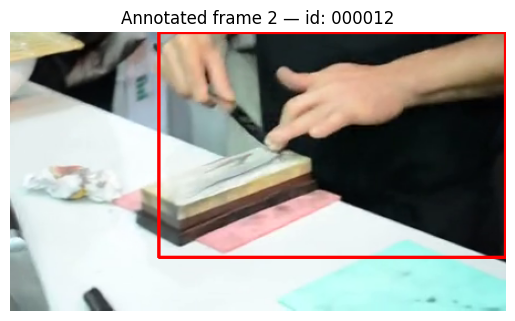

In [29]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input_oo3.shape[0])
any_frame = annotated_input_oo3[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — id: {sample_oo3['id']}")
plt.axis('off')
plt.show()

## OO3-5. Save annotated video to disk

In [31]:
from torchcodec.encoders import VideoEncoder

dump_dir = "/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump"
os.makedirs(dump_dir, exist_ok=True)
output_video_path_oo3 = os.path.join(dump_dir, f"oo3_ann_{sample_oo3['id']}.mp4")
VideoEncoder(annotated_input_oo3.to(torch.uint8), frame_rate=4).to_file(output_video_path_oo3)
print("wrote:", output_video_path_oo3)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serving/dump/oo3_ann_000012.mp4


## OO3-6. Build the chat request and send to vLLM

In [32]:
# def create_user_prompt(video_summary, question, concept_captions, answer=None):
#     prompt = f"Video summary: {video_summary}\n"
#     prompt += f"Question: {question}\n"
#     prompt += "Relevant concepts and their captions:\n"
#     for concept, caption in concept_captions.items():
#         prompt += f"- {concept}: {caption}\n"
#     if answer is not None:
#         prompt += f"Answer: {answer}\n"
#     return prompt
def create_user_prompt(video_summary, question, concept_captions, answer=None):
    prompt = f"{video_summary}\n"
    prompt += "Red bounding box annotated objects/entities in the video:\n"
    for concept, caption in concept_captions.items():
        prompt += f"- {concept}: {caption}\n"
    prompt += f"Question: {question}\n"
    if answer is not None:
        prompt += f"Ground Truth Answer: {answer}\n"
    return prompt

# load the PLM rcap outputs (video summary + per-concept captions) for the current sample
RCAP_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_plm_rcap"
rcap = json.load(open(os.path.join(RCAP_DIR, "samples", f"{sample_oo3['id']}.json")))

user_prompt = create_user_prompt(
    video_summary=rcap["video_summary"],
    question=sample_oo3["question"],
    concept_captions=rcap["concept_captions"],
    answer=sample_oo3["answer"],
)
print(user_prompt)

The video features a man sharpening a knife on a stone while a group of people observe.
The man is wearing a black shirt and is standing at a white table. He is holding a knife in his right hand and is rubbing it against a rectangular-shaped stone. He is moving the knife back and forth against the stone. He then picks up a piece of paper and rubs it against the knife. He then puts the knife down and picks up a roll of paper towels.

There are several people standing around the man, observing him. There are also several knives on the table.
Red bounding box annotated objects/entities in the video:
- person: A man is sharpening a knife on a sharpening stone. he then cleans the knife with a paper towel and then puts the knife down on the table. he then picks up a tissue roll and then puts it down on the table. he then picks up the knife again.
- paper towel roll: A tissue roll is placed on the table and a man picks it up and uses it to wipe the knife.
Question: What is used to clean the k

In [35]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"
model = "Qwen/Qwen2.5-VL-72B-Instruct"

SYSTEM_PROMPT_PATH = "/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/cot/v6.md"
with open(SYSTEM_PROMPT_PATH, "r") as f:
    SYSTEM_PROMPT = f.read()

n_frames = annotated_input_oo3.shape[0]
frame_prompt = "".join(f"Frame {i}: <image>\n" for i in range(n_frames))

message_oo3 = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {"type": "text", "text": frame_prompt + user_prompt},
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path_oo3},
                # "VIDEO_MIN_PIXELS": 512 * 28 * 28,
                "VIDEO_MAX_PIXELS": 1024 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

In [36]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message_oo3,
    max_tokens=768,
    seed=42,
    temperature=0,
)
response_text = chat_response.choices[0].message.content
print(response_text)

<think>
Let me think about this step-by-step. The man is seen sharpening a knife on a stone, which is a common practice to maintain the edge of a blade. After sharpening, he uses a piece of paper to test the sharpness of the knife. This is a standard method to check if the knife has been properly sharpened. Once he confirms the sharpness, he proceeds to clean the knife.

Now, the question is about what is used to clean the knife after the dirty paper towel is thrown away. In the video, I notice that there is a roll of paper towels on the table. The man picks up this roll and tears off a new sheet. This new, clean paper towel is then used to wipe the knife. The presence of the red bounding box around the paper towel roll emphasizes its importance in this context.

So, the man uses a clean paper towel from the roll to wipe the knife after discarding the dirty one. This makes sense because using a clean paper towel ensures that no residue from the previous cleaning remains on the knife, m

In [26]:
print(f"Question: {sample_oo3['question']}")
print(f"Ground truth answer: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")

print(f"Sample {SAMPLE_IDX}  id={sample_oo3['id']}")
print(f"Q: {sample_oo3['question']}")
print(f"A: {sample_oo3['answer']}")
print(f"CoT: {sample_oo3['reasoning_process']}")
print(f"Concepts: {[c['concept'] for c in sample_entry['concepts']]}")

Question: What is used to clean the knife after the dirty paper towel is thrown away?
Ground truth answer: A clean paper towel from a roll is used to wipe the knife clean.
CoT: The video shows the <obj>person</obj><box>[0.11, 0.0, 0.85, 1.0]</box>at<t>103.5</t>s taking a <obj>paper towel roll</obj><box>[0.21, 0.23, 0.37, 0.36]</box>at<t>103.5</t>s after discarding the previous one. Subsequently, the <obj>person</obj><box>[0.11, 0.0, 0.85, 1.0]</box>at<t>105.0</t>s is seen holding a fresh piece of paper towel. Finally, the person uses this paper towel to wipe the knife clean. This confirms a new paper towel is used for cleaning.
Sample 12  id=000012
Q: What is used to clean the knife after the dirty paper towel is thrown away?
A: A clean paper towel from a roll is used to wipe the knife clean.
CoT: The video shows the <obj>person</obj><box>[0.11, 0.0, 0.85, 1.0]</box>at<t>103.5</t>s taking a <obj>paper towel roll</obj><box>[0.21, 0.23, 0.37, 0.36]</box>at<t>103.5</t>s after discarding t